In [1]:
import numpy as np
import pandas as pd
import os
from urllib.parse import unquote
import random
from time import sleep
import pickle
import json
import copy
import re
import regex
import matplotlib.pyplot as plt
import ast
import parse
import yaml
import sys
from transformers import AutoTokenizer
sys.path.append('../')
from utils import effective_path, extract_json_from_response, get_paths_real_sample





%load_ext autoreload
%autoreload 2

random.seed(42)
pd.set_option('display.max_colwidth', 1000)

PATH_IN = '../../data/wikispeedia/wikispeedia_paths-and-graph/'
LOGS_PATH = '../../logs/inference/'

/dlabdata1/charneca/miniconda3/envs/wikinav/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


# Analyse Sweep Data

In [23]:
# Load real paths data
paths_real_df = pd.read_csv(os.path.join(PATH_IN, 'paths_real_processed.tsv'), sep='\t', low_memory=False)
# Load all run data
MULTIRUN_PATH = os.path.join(LOGS_PATH, 'multiruns/temperature_tests/2023-10-30_12-43-08')
identifier = 'model.temperature'

folders = [os.path.join(MULTIRUN_PATH, f) for f in os.listdir(MULTIRUN_PATH) if os.path.isdir(os.path.join(MULTIRUN_PATH, f)) and os.path.exists(os.path.join(MULTIRUN_PATH, f, 'agent_runs.tsv'))]
folders += [os.path.join(LOGS_PATH, 'multiruns/prompt_variations_runai/2023-10-27_18-58-38/0')]

runs = [] # list of dicts {config, df}
for folder in folders:
    # each config is saved in the file .hydra/overrides.yaml, load the yaml and save the config to a dict
    with open(os.path.join(folder, '.hydra/config.yaml'), 'r') as f:
            config = yaml.safe_load(f)    
            config_dict = {}
            identifier_keys = identifier.split('.')
            # go into the dict until the last key (ex: if identifier = 'model.temperature', go into config['model']['temperature'])
            for key in identifier_keys[:-1]:
                config = config[key]
            config_dict[identifier] = config[identifier_keys[-1]]

    config_dict['run_id'] = int(folder.split('/')[-1])

    config_dict['df'] = pd.read_csv(os.path.join(folder, 'agent_runs.tsv'), sep='\t')
    runs.append(config_dict)

runs = sorted(runs, key=lambda x: x['run_id'])
print([(key, runs[0][key]) for key in runs[0].keys() if key != 'df'])
print(f"Folders: {folders}")

[('model.temperature', 0.2), ('run_id', 0)]
Folders: ['../../logs/inference/multiruns/temperature_tests/2023-10-30_12-43-08/0', '../../logs/inference/multiruns/temperature_tests/2023-10-30_12-43-08/1', '../../logs/inference/multiruns/temperature_tests/2023-10-30_12-43-08/2', '../../logs/inference/multiruns/temperature_tests/2023-10-30_12-43-08/3', '../../logs/inference/multiruns/prompt_variations_runai/2023-10-27_18-58-38/0']


In [25]:
# Error types:
# - "Try a different page" = PageNotInCands
# - "Cannot go back any further" = BackOnFirstPage
# - else = BadResponse
for run in runs:
    print("\nRun config:")
    for key in run.keys():
        if key != 'df':
            print(f"\t{key} = {run[key]}")
    run_df = run['df']
    # add columns
    run_df['error_type'] = run_df['action'].apply(lambda x:
                                                "no_error" if "{'next_page'" in x else
                                                "PageNotInCands" if "Try a different page" in x else
                                                "BackOnFirstPage" if "Cannot go back any further" in x else
                                                "BadResponse")
    num_runs = len(run_df.query('is_finished==True'))
    num_errors = run_df.query('is_finished==True')['num_errors'].sum()
    num_actions = run_df.query('is_finished==True')['num_actions'].sum()

    print("Total number of runs:", num_runs)
    print("% of successful runs:", round(len(run_df.query('is_finished_reason=="success"'))/num_runs*100, 1))
    print("% of failed runs because of max_tries (too many errors):", round(len(run_df.query('is_finished_reason=="max_tries"'))/num_runs*100, 1))
    print("% of failed runs because of max_actions (too many actions):", round(len(run_df.query('is_finished_reason=="max_actions"'))/num_runs*100, 1))
    print("% of error actions:", round(run_df.query('is_finished==True')['num_errors'].sum()/run_df.query('is_finished==True')['num_actions'].sum()*100, 1))
    print("\tFrom which:")
    print("\t% of PageNotInCands:", round(len(run_df.query('error_type=="PageNotInCands"'))/num_errors*100, 1))
    print("\t% of BackOnFirstPage:", round(len(run_df.query('error_type=="BackOnFirstPage"'))/num_errors*100, 1))
    print("\t% of BadResponse:", round(len(run_df.query('error_type=="BadResponse"'))/num_errors*100, 1))
    


Run config:
	model.temperature = 0.2
	run_id = 0
Total number of runs: 100
% of successful runs: 33.0
% of failed runs because of max_tries (too many errors): 55.0
% of failed runs because of max_actions (too many actions): 12.0
% of error actions: 35.3
	From which:
	% of PageNotInCands: 98.4
	% of BackOnFirstPage: 0.8
	% of BadResponse: 0.8

Run config:
	model.temperature = 0.7
	run_id = 0
Total number of runs: 100
% of successful runs: 38.0
% of failed runs because of max_tries (too many errors): 50.0
% of failed runs because of max_actions (too many actions): 12.0
% of error actions: 31.9
	From which:
	% of PageNotInCands: 97.6
	% of BackOnFirstPage: 0.8
	% of BadResponse: 1.6

Run config:
	model.temperature = 0.5
	run_id = 1
Total number of runs: 100
% of successful runs: 37.0
% of failed runs because of max_tries (too many errors): 50.0
% of failed runs because of max_actions (too many actions): 13.0
% of error actions: 35.2
	From which:
	% of PageNotInCands: 98.3
	% of BackOnFir

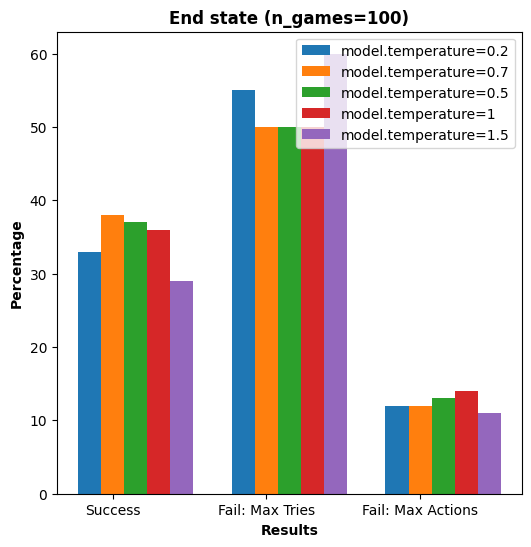

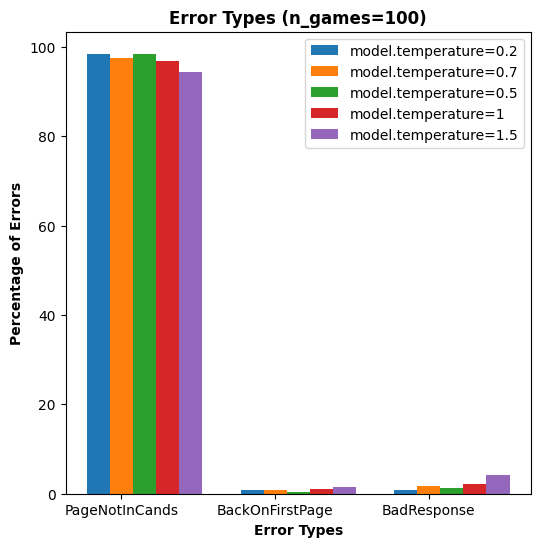

Text(0.5, 1.0, 'Percentage of actions that are errors (n_games=100)')

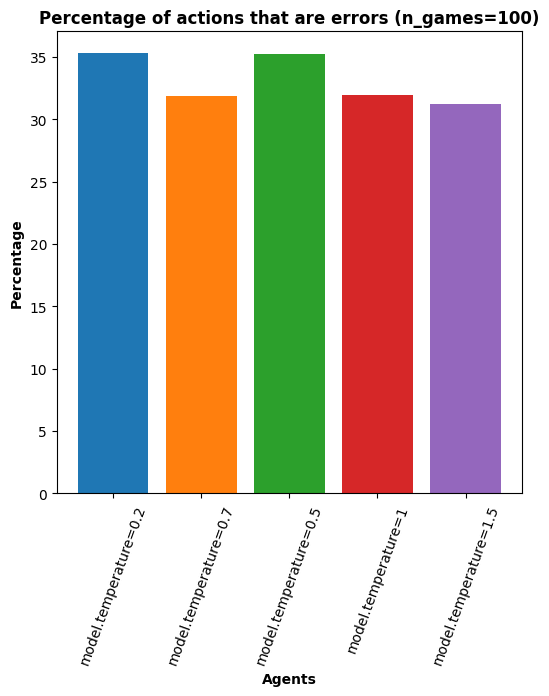

In [26]:
import matplotlib.pyplot as plt
import numpy as np

# Number of runs
n_runs = len(runs)

# Lists for accumulating results and error types
successful_runs = []
max_tries_runs = []
max_actions_runs = []
num_errors_runs = []

page_not_in_cands_errors = []
back_on_first_page_errors = []
bad_response_errors = []

for run in runs:
    run_df = run['df']

    # Existing code to determine error type
    run_df['error_type'] = run_df['action'].apply(lambda x:
                                                "no_error" if "{'next_page'" in x else
                                                "PageNotInCands" if "Try a different page" in x else
                                                "BackOnFirstPage" if "Cannot go back any further" in x else
                                                "BadResponse")
    num_runs = len(run_df.query('is_finished==True'))
    num_actions = run_df.query('is_finished==True')['num_actions'].sum()
    num_errors = run_df.query('is_finished==True')['num_errors'].sum()

    # Accumulate data for each run
    successful_runs.append(len(run_df.query('is_finished_reason=="success"'))/num_runs*100)
    max_tries_runs.append(len(run_df.query('is_finished_reason=="max_tries"'))/num_runs*100)
    max_actions_runs.append(len(run_df.query('is_finished_reason=="max_actions"'))/num_runs*100)
    
    num_errors_runs.append(num_errors/num_actions*100)
    page_not_in_cands_errors.append(len(run_df.query('error_type=="PageNotInCands"'))/num_errors*100)
    back_on_first_page_errors.append(len(run_df.query('error_type=="BackOnFirstPage"'))/num_errors*100)
    bad_response_errors.append(len(run_df.query('error_type=="BadResponse"'))/num_errors*100)


bar_width = 0.15
r = np.arange(3)  # For three categories: 'success', 'max_tries', 'max_actions'
r_errors = np.arange(3)  # For three error types

# Plot for run results
plt.figure(figsize=(6,6))
for i in range(n_runs):
    offsets = [j+(bar_width*i) for j in r]
    plt.bar(offsets, [successful_runs[i], max_tries_runs[i], max_actions_runs[i]], width=bar_width, label=f"{identifier}={runs[i][identifier]}")

plt.xlabel('Results', fontweight='bold')
plt.ylabel('Percentage', fontweight='bold')
plt.xticks([r + bar_width for r in range(3)], ['Success', 'Fail: Max Tries', 'Fail: Max Actions'])
plt.title('End state (n_games=100)', fontweight='bold')
plt.legend()
plt.show()

# Plot for error types
plt.figure(figsize=(6,6))
for i in range(n_runs):
    offsets = [j+(bar_width*i) for j in r_errors]
    plt.bar(offsets, [page_not_in_cands_errors[i], back_on_first_page_errors[i], bad_response_errors[i]], width=bar_width, label=f"{identifier}={runs[i][identifier]}")

plt.xlabel('Error Types', fontweight='bold')
plt.ylabel('Percentage of Errors', fontweight='bold')
# use a logy scale
plt.xticks([r + bar_width for r in range(3)], ['PageNotInCands', 'BackOnFirstPage', 'BadResponse'])
plt.title('Error Types (n_games=100)', fontweight='bold')
plt.legend()
plt.show()

# Plot for number of errors
plt.figure(figsize=(6,6))
for i in range(n_runs):
    plt.bar(i, num_errors_runs[i], label=f"{identifier}={runs[i][identifier]}")

plt.xlabel('Agents', fontweight='bold')
plt.ylabel('Percentage', fontweight='bold')
plt.xticks([r for r in range(n_runs)], [f"{identifier}={runs[i][identifier]}" for i in range(n_runs)], rotation=70)
plt.title('Percentage of actions that are errors (n_games=100)', fontweight='bold')


In [17]:
run_df = runs[3]['df']
run_df[run_df['action'].apply(lambda x: "{'next_page'" not in x and "Try a different page" not in x)]['action'].tolist()

['Cannot go back any further.',
 'Cannot go back any further.',
 'Cannot go back any further.',
 'Cannot go back any further.',
 "Expecting ',' delimiter: line 1 column 44 (char 43)",
 'Cannot go back any further.',
 'Unterminated string starting at: line 1 column 14 (char 13)',
 'Unterminated string starting at: line 1 column 15 (char 14)',
 'Cannot go back any further.',
 'Cannot go back any further.',
 "Expecting ':' delimiter: line 1 column 5 (char 4)",
 'Invalid action: {}',
 'Invalid action: {}',
 'Unterminated string starting at: line 1 column 15 (char 14)',
 "Expecting ':' delimiter: line 1 column 5 (char 4)",
 "Expecting ':' delimiter: line 1 column 5 (char 4)"]

In [18]:
run_df[run_df['action'].apply(lambda x: "{'next_page'" not in x and "Try a different page" not in x)]['response'].tolist()

['{"next_page": "NA"}',
 '{"next_page": "NA"}',
 '{"next_page": "NA"}',
 '{"next_page": "NA"}',
 '{"next_page": "Tropical Storm Harvey (2005")}',
 '{"next_page": "NA"}',
 '{"next_page":",Tropical_Storm_Harvey_(2005)}',
 '{"next_page": "Tropical Storm Leslie (2000}")',
 '{"next_page": "NA"}',
 '{"next_page": "NA"}',
 '{"{"next_page": "Tropical Storm Harvey (2005)"}}',
 '{"source": "Thalassemia", "target": "Sanskrit", "links": ["Acts_of_Union_1707", "Adam_Smith", "Airbus", "Anglican_Communion", "Anne_of_Great_Britain", "Archbishop_of_Canterbury", "Arctic_Monkeys", "Argentina", "Arsenal_F.C.", "Atlantic_Ocean", "BAE_Systems", "Bangladesh", "Belfast", "Ben_Jonson",',
 '{"source": "Thalassemia", "target": "Sanskrit", "links": ["Acts_of_Union_1707", "Adam_Smith", "Airbus", "Anglican_Communion", "Anne_of_Great_Britain", "Archbishop_of_Canterbury", "Arctic_Monkeys", "Argentina", "Arsenal_F.C.", "Atlantic_Ocean", "BAE_Systems", "Bangladesh", "Belfast", "Ben_Jonson",',
 '{"next_page": "Tropical 

In [7]:
# For the old agent_runs.tsv format
runs[0]['df'].query('ending=="success" and num_actions>0 and path_length==spl')[['src','tgt','path_length', 'spl', 'shepl', 'path']].rename(columns={'path':'agent_effective_path', 'spl': 'shortest_possible_path_len', 'shepl': 'shortest_human_effective_path_len'})
#,'visited_pages', 'path']]

,src,tgt,path_length,shortest_possible_path_len,shortest_human_effective_path_len,agent_effective_path
77,Cricket,President_of_the_United_States,3,3.0,3.0,Cricket;Sri Lanka;United States
87,1st_century_BC,England,2,2.0,NaN,1st_century_BC;18th century
90,A_cappella,Liverpool_F.C.,3,3.0,4.0,A_cappella;The Beatles;Liverpool


/tmp/ipykernel_1312355/2958376329.py:6: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  runs_df['last_page'] = runs_df['visited_pages'].apply(lambda x: x.split(';')[-1])
/tmp/ipykernel_1312355/2958376329.py:7: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  runs_df['num_links_on_last_page'] = runs_df['last_page'].apply(lambda x: article_links_df.query('article==@x')['num_links'].values[0] if x in article_links_df['article'].values else 0)


Run configuration:
[('agent.fewshot', '5'), ('agent.max_actions', '100'), ('agent', 'link_click_dfs_agent'), ('+agent.use_feedback', 'False'), ('+agent.fewshot_click_types', 'None'), ('run_name', 'agent_sweep'), ('run_id', 0)]

 Total number of runs: 95

Percentage of successful runs: 22.1

Percentage of failed runs because of max_tries (too many errors) 77.9

Percentage of failed runs because of max_actions (too many actions) 0.0

Top 5 longest paths:
                 src                                  tgt  path_length
72    Water_Buffalo                           EastEnders           86
30             Dove                             Hawk-Eye           75
33         Bushbuck                      Acorn_Computers           65
81  Carcinus_maenas                       Mount_Pinatubo           65
2    Arctic_Monkeys  National_parks_of_England_and_Wales           44

Top 5 pages that it gets stuck on the most with errors last_page
France        3
Iran          3
India         3
Islam   

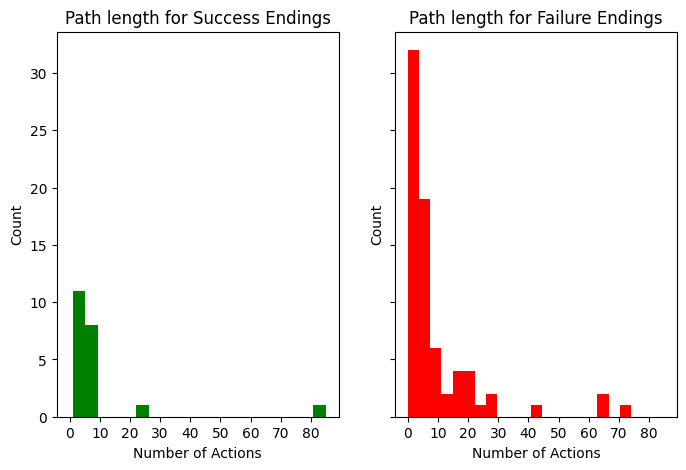

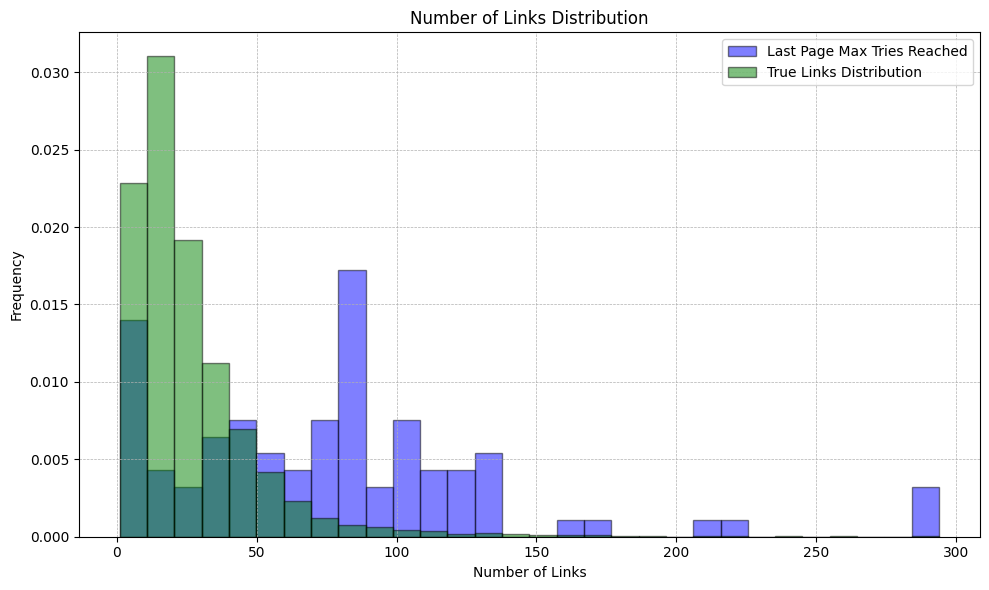

In [89]:
# get article links for some analysis
article_links_df = pd.read_csv(os.path.join(PATH_IN, "article_links.tsv"), sep="\t")
article_links_df['num_links'] = article_links_df.apply(lambda x: len(x['links'].split(";")), axis=1)

runs_df = runs[0]['df'].query('spl>1')
runs_df['last_page'] = runs_df['visited_pages'].apply(lambda x: x.split(';')[-1])
runs_df['num_links_on_last_page'] = runs_df['last_page'].apply(lambda x: article_links_df.query('article==@x')['num_links'].values[0] if x in article_links_df['article'].values else 0)

print("Run configuration:")
print([(key, runs[0][key]) for key in runs[0].keys() if key != 'df'])
print("\n Total number of runs:", len(runs_df))
print("\nPercentage of successful runs:", round(len(runs_df.query('ending=="success"'))/len(runs_df)*100, 1))
print("\nPercentage of failed runs because of max_tries (too many errors)", round(len(runs_df.query('ending=="max_tries"'))/len(runs_df)*100, 1))
print("\nPercentage of failed runs because of max_actions (too many actions)", round(len(runs_df.query('ending=="max_actions"'))/len(runs_df)*100, 1))
print("\nTop 5 longest paths:\n", runs_df.sort_values(by='path_length', ascending=False).head(5)[['src', 'tgt', 'path_length']])
print("\nTop 5 pages that it gets stuck on the most with errors", runs_df.query("ending=='max_tries'")['last_page'].value_counts().head(5))

# Plotting histograms
fig, axs = plt.subplots(1, 2, figsize=(8, 5), sharey=True, sharex=True)
axs[0].set_xticks(range(0, max(runs_df['num_actions']), 10))
axs[1].set_xticks(range(0, max(runs_df['num_actions']), 10))
axs[0].hist(runs_df[runs_df['ending'] == 'success']['num_actions'], bins=20, color='green')
axs[0].set_title('Path length for Success Endings')
axs[0].set_xlabel('Number of Actions')
axs[0].set_ylabel('Count')

axs[1].hist(runs_df[runs_df['ending'] != 'success']['num_actions'], bins=20, color='red')
axs[1].set_title('Path length for Failure Endings')
axs[1].set_xlabel('Number of Actions')
axs[1].set_ylabel('Count')

plt.show()

plt.figure(figsize=(10, 6))

# Histogram for runs_df
plt.hist(runs_df['num_links_on_last_page'], bins=30, color='blue', edgecolor='black', alpha=0.5, label='Last Page Max Tries Reached', density=True)
plt.xlabel('Number of Links')
plt.ylabel('Frequency')
plt.title('Number of Links Distribution')
plt.grid(True, which='both', linestyle='--', linewidth=0.5)

# Histogram for article_links_df
plt.hist(article_links_df['num_links'], bins=30, color='green', edgecolor='black', density=True, alpha=0.5, label='True Links Distribution')

# Add legend
plt.legend(loc='upper right')

plt.tight_layout()
plt.show()

Notes:
 - When there are a very low amount of links, the agent seems to make up stuff.
    - Example: last_page=Inductance, response_history = ... '{"next_page": "Electric_circuit"}', '{"next_page": "Galvani"}', '{"next_page": "Galvanism"}'
 - If the page has too many links, it just tries to click on the target: India (81 links), Iran (108 links) France (85 links), etc
    - Example: last_page=France, tgt=Marshall_Plan, response_history = ... '{"next_page": "Marshall_Plan"}', '{"next_page": "Marshall_Plan"}', '{"next_page": "Marshall_Plan"}'
    - Example: last_page=India, tgt=Bill_Gates, response_history = .. '{"next_page": "Bill Gates"}', '{"next_page": "Bill Gates"}', '{"next_page": "Bill Gates"}'
    - **curiously** it only got stuck on United_States 1 time, while the other big pages it got stuck 3 or 2

In [68]:
runs_df.query("ending=='max_tries' and last_page=='Iran'")[['src', 'tgt', 'last_page', 'num_links_on_last_page', 'ending', 'num_actions', 'path', 'response_history']]
#article_links_df.query("article=='Inductance'")

,src,tgt,last_page,num_links_on_last_page,ending,num_actions,path,response_history
27,Tooth_development,Train,Iran,108,max_tries,5,Tooth_development;Vitamin;Thiamine;Sulfur;Turkmenistan;Iran,"['{""next_page"": ""Vitamin""}', '{""next_page"": ""Thiamine""}', '{""next_page"": ""Sulfur""}', '{""next_page"": ""Train""}', '{""next_page"": ""Train""}', '{""next_page"": ""Turkmenistan""}', '{""next_page"": ""Iran""}', '{""next_page"": ""Train""}', '{""next_page"": ""Train""}', '{""next_page"": ""Train""}']"
66,Kosovo,Giant_Panda,Iran,108,max_tries,3,Kosovo;Islam;Qur'an;Iran,"['{""next_page"": ""Islam""}', '{""next_page"": ""Qur\'an""}', '{""next_page"": ""Iran""}', '{""next_page"": ""Giant Panda""}', '{""next_page"": ""Giant Panda""}', '{""next_page"": ""Giant Panda""}']"
89,William_N._Page,African_Grey_Parrot,Iran,108,max_tries,11,William_N._Page;Italy;Austria;Holy Roman Empire;Aachen;Paul of Tarsus;Athens;Parthenon;Persian_Empire;Islam;Mongol Empire;Iran,"['{""next_page"": ""Italy""}', '{""next_page"": ""African_Grey_Parrot""}', '{""next_page"": ""Austria""}', '{""next_page"": ""Austria""}', '{""next_page"": ""Austrian_Czars""}', '{""next_page"": ""Holy Roman Empire""}', '{""next_page"": ""Aachen""}', '{""next_page"": ""Paul of Tarsus""}', '{""next_page"": ""Athens""}', '{""next_page"": ""Africa""}', '{""next_page"": ""Athens""}', '{""next_page"": ""Parthenon""}', '{""next_page"": ""Persian_Empire""}', '{""next_page"": ""Islam""}', '{""next_page"": ""Mongol Empire""}', '{""next_page"": ""Iran""}', '{""next_page"": ""African_Grey_Parrot""}', '{""next_page"": ""African_Grey_Parrot""}', '{""next_page"": ""African_Grey_Parrot""}']"


In [36]:
runs_df['path'].apply(lambda x: x.split(';')[-1]).value_counts().head(10)

path
United States    3
India            3
France           3
Iran             3
Tanzania         3
Sulfur           2
Russia           2
Somalia          2
Gold             2
Islam            2
Name: count, dtype: int64

In [15]:
for run in runs:
    print(f"Config run_id={run['run_id']}, agent type={run['agent']}, fewshot={run['agent.fewshot']}")
    print(f"Number of completed games: {len(run['df'].query('reached_goal==True'))}")
    print()

runs[0]['df'].query("reached_goal == False")[['src', 'tgt', 'path', 'num_actions', 'response_history']]

Config run_id=0, agent type=link_click_dfs_agent, fewshot=5


UndefinedVariableError: name 'reached_goal' is not defined

In [26]:
# Add extra columns to the dfs

# get the llama2 tokenizer
tokenizer = AutoTokenizer.from_pretrained("meta-llama/Llama-2-7b-chat-hf")

# get article links for some analysis
article_links_df = pd.read_csv(os.path.join(PATH_IN, "article_links.tsv"), sep="\t")
article_links_df['num_links'] = article_links_df.apply(lambda x: len(x['links'].split(";")), axis=1)

for run in runs:
    print(run['run_id'])
    run['df']['end_page'] = run['df'].apply(lambda x: x['path'].split(";")[-1], axis=1)
    # response history is a string of the form ['response1', 'response2', ...], we have to use parse
    run['df']['end_response'] = run['df'].apply(lambda x: ast.literal_eval(x['response_history'])[-1], axis=1)
    run['df']["end_user_prompt"]=run['df'].apply(lambda x: ast.literal_eval(x['user_prompt_history'])[-1], axis=1)
    run['df']["end_user_prompt_num_tokens"]=run['df'].apply(lambda x: len(tokenizer.tokenize(x['end_user_prompt'])), axis=1)
    run['df']['end_next_page'] = run['df'].apply(lambda x: parse.search("\"next_page\": \"{}\"", x['end_response'])[0], axis=1)
    run['df']['reached_goal'] = run['df'].apply(lambda x: x['end_page'] == x['tgt'], axis=1)
    run['df']['path_length'] = run['df'].apply(lambda x: len(x['path'].split(";")) - 1, axis=1)
    run['df']['end_response_extracted_json'] = run['df'].apply(lambda x: extract_json_from_response(x['end_response']), axis=1)
    run['df'] = pd.merge(run['df'], article_links_df, left_on='end_page', right_on='article', how='left')

    # rename num_links to end_page_num_links
    run['df'].rename(columns={'num_links': 'end_page_num_links'}, inplace=True)
    run['df'].rename(columns={'links': 'end_page_links'}, inplace=True)



0
1


TypeError: 'NoneType' object is not subscriptable

# Analyse agent run data

In [100]:
PATH_RUNS = "../../logs/inference/multiruns/multiturn_demo_comparison/2023-10-11_17-46-25"

system_demo_df = pd.read_csv(os.path.join(PATH_RUNS, "0/agent_runs.tsv"), sep="\t")
multiturn_demo_df = pd.read_csv(os.path.join(PATH_RUNS, "1/agent_runs.tsv"), sep="\t")

# get the llama2 tokenizer
tokenizer = AutoTokenizer.from_pretrained("meta-llama/Llama-2-7b-chat-hf")

# get article links for some analysis
article_links_df = pd.read_csv(os.path.join(PATH_IN, "article_links.tsv"), sep="\t")
article_links_df['num_links'] = article_links_df.apply(lambda x: len(x['links'].split(";")), axis=1)

# unite these two dfs, and add a column to indicate which system it is
system_demo_df['fewshot_mode'] = 'system_prompt'
multiturn_demo_df['fewshot_mode'] = 'multiturn'
runs_df = pd.concat([system_demo_df, multiturn_demo_df], ignore_index=True)

runs_df['end_page'] = runs_df.apply(lambda x: x['path'].split(";")[-1], axis=1)
# response history is a string of the form ['response1', 'response2', ...], we have to use parse
runs_df['end_response'] = runs_df.apply(lambda x: ast.literal_eval(x['response_history'])[-1], axis=1)
runs_df["end_user_prompt"]=runs_df.apply(lambda x: ast.literal_eval(x['user_prompt_history'])[-1], axis=1)
runs_df["end_user_prompt_num_tokens"]=runs_df.apply(lambda x: len(tokenizer.tokenize(x['end_user_prompt'])), axis=1)
runs_df['end_next_page'] = runs_df.apply(lambda x: parse.search("\"next_page\": \"{}\"", x['end_response'])[0], axis=1)
runs_df['reached_goal'] = runs_df.apply(lambda x: x['end_page'] == x['tgt'], axis=1)
runs_df['path_length'] = runs_df.apply(lambda x: len(x['path'].split(";")) - 1, axis=1)
runs_df['end_response_extracted_json'] = runs_df.apply(lambda x: extract_json_from_response(x['end_response']), axis=1)
runs_df = pd.merge(runs_df, article_links_df, left_on='end_page', right_on='article', how='left')

# rename num_links to end_page_num_links
runs_df.rename(columns={'num_links': 'end_page_num_links'}, inplace=True)
runs_df.rename(columns={'links': 'end_page_links'}, inplace=True)


In [72]:
runs_df.head()


,agent_id,agent_type,src,tgt,path,fewshot,num_actions,num_errors,user_prompt_history,response_history,...,end_response,end_user_prompt,end_user_prompt_num_tokens,end_next_page,reached_goal,path_length,end_response_extracted_json,article,links,end_page_num_links
0,0,LinkClickAgent,Albinism,Tungsten,Albinism;Niger;United_States;Vietnam;Cambodia;...,3,8,2,"[""User: I'm currently on the page Albinism and...","['Assistant:\n{\n ""next_page"": ""Niger""\n}', '...",...,"Assistant:\n{\n ""next_page"": ""Tungsten""\n}",User: I'm currently on the page United_States ...,1869,Tungsten,False,8,"{\n ""next_page"": ""Tungsten""\n}",United_States,Abraham_Lincoln;Advertising;Agriculture;Americ...,294.0
1,1,LinkClickAgent,Heraclius,Gender,Heraclius;Muhammad;Islam;Sultan;Egypt;Sudan,3,5,2,"[""User: I'm currently on the page Heraclius an...","['Assistant:\n{\n ""next_page"": ""Muhammad""\n}'...",...,"Assistant:\n{\n ""next_page"": ""Gender""\n}",User: I'm currently on the page Sudan and the ...,747,Gender,False,5,"{\n ""next_page"": ""Gender""\n}",Sudan,Afghanistan;Africa;African_Union;Albania;Alger...,132.0
2,2,LinkClickAgent,"Salt_Lake_City,_Utah",Drum_and_bass,"Salt_Lake_City,_Utah;Jazz;Miles_Davis;Jazz;Mil...",3,7,2,"[""User: I'm currently on the page Salt_Lake_Ci...","['Assistant:\n{\n ""next_page"": ""Jazz""\n}', 'A...",...,"Assistant:\n{\n ""next_page"": ""Drum_and_bass""\n}",User: I'm currently on the page United_States ...,1873,Drum_and_bass,False,7,"{\n ""next_page"": ""Drum_and_bass""\n}",United_States,Abraham_Lincoln;Advertising;Agriculture;Americ...,294.0
3,3,LinkClickAgent,History_of_post-Soviet_Russia,Oviraptor,History_of_post-Soviet_Russia;Vladimir_Lenin;M...,3,4,2,"[""User: I'm currently on the page History_of_p...","['Assistant:\n{\n ""next_page"": ""Vladimir_Leni...",...,"Assistant:\n{\n ""next_page"": ""Oviraptor""\n}",User: I'm currently on the page United_States ...,1871,Oviraptor,False,4,"{\n ""next_page"": ""Oviraptor""\n}",United_States,Abraham_Lincoln;Advertising;Agriculture;Americ...,294.0
4,4,LinkClickAgent,Archbishop_of_Canterbury,Dead_Sea,Archbishop_of_Canterbury;Thomas_Cranmer;Willia...,3,5,2,"[""User: I'm currently on the page Archbishop_o...","['Assistant:\n{\n ""next_page"": ""Thomas_Cranme...",...,"Assistant:\n{\n ""next_page"": ""Dead_Sea""\n}",User: I'm currently on the page London and the...,666,Dead_Sea,False,5,"{\n ""next_page"": ""Dead_Sea""\n}",London,Alfred_the_Great;Ancient_Rome;Anglicanism;Arse...,102.0


In [77]:
runs_df['end_response_extracted_json'].value_counts()

end_response_extracted_json
{\n  "next_page": "Florida_East_Coast_Railway"\n}    2
{\n  "next_page": "Franklin_D._Roosevelt"\n}         2
{\n  "next_page": "Unix"\n}                          2
{\n  "next_page": "Mark_Twain_House"\n}              2
{\n  "next_page": "Magellanic_Penguin"\n}            2
{\n  "next_page": "Uzbekistan"\n}                    2
{\n  "next_page": "Oviraptor"\n}                     2
{\n  "next_page": "Drum_and_bass"\n}                 2
{\n  "next_page": "Indonesia"\n}                     2
{\n  "next_page": "Nazi_Germany"\n}                  1
{\n  "next_page": "Sega"\n}                          1
{\n  "next_page": "Tibet"\n\n}                       1
{\n  "next_page": "Ireland"\n\n}                     1
{\n  "next_page": "Dr._Seuss"\n}                     1
{\n  "next_page": "Law"\n\n}                         1
{\n  "next_page": "Malaria"\n}                       1
{\n  "next_page": "Tanzania"\n}                      1
{\n  "next_page": "Domestic_goat"\n} 

## Fewshot in system prompt

In [50]:
print("Number of failed runs because of too many actions: ", runs_df.query("fewshot_mode == 'system_prompt' and reached_goal == False and num_actions==15").count().iloc[0])
print("Number of failed runs because of too many invalid actions: ", runs_df.query("fewshot_mode == 'system_prompt' and reached_goal == False and num_errors==2").count().iloc[0])

Number of failed runs because of too many actions:  2
Number of failed runs because of too many invalid actions:  22


In [93]:
print("Number of unparseable json outputs: ", runs_df.query("fewshot_mode == 'system_prompt' and reached_goal == False and end_response_extracted_json.isna()").count().iloc[0])
print(runs_df.query("fewshot_mode == 'system_prompt' and end_response_extracted_json.isna()").end_response.tolist())

Number of unparseable json outputs:  0
[]


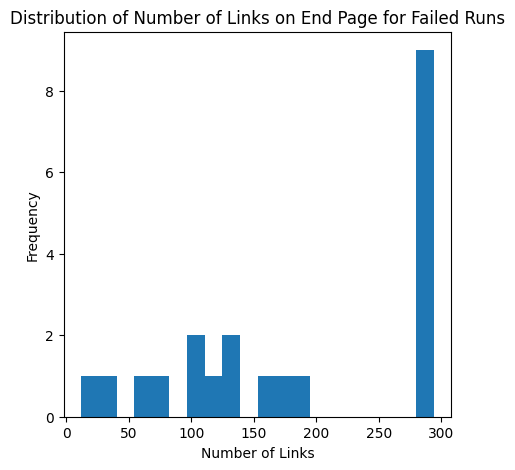

In [64]:
plt.figure(figsize=(5, 5))

runs_df.query("fewshot_mode == 'system_prompt' and num_errors == 2").end_page_num_links.hist(bins=20, grid=False)

plt.title('Distribution of Number of Links on End Page for Failed Runs')
plt.xlabel('Number of Links')
plt.ylabel('Frequency')

plt.show()


In [78]:
runs_df.query("fewshot_mode == 'system_prompt' and num_errors == 2 and end_page == 'United_States'")[['src', 'tgt', 'path', 'num_errors', 'end_page', 'end_response', 'end_response_extracted_json', 'end_next_page']]


,src,tgt,path,num_errors,end_page,end_response,end_response_extracted_json,end_next_page
0,Albinism,Tungsten,Albinism;Niger;United_States;Vietnam;Cambodia;...,2,United_States,"Assistant:\n{\n ""next_page"": ""Tungsten""\n}","{\n ""next_page"": ""Tungsten""\n}",Tungsten
2,"Salt_Lake_City,_Utah",Drum_and_bass,"Salt_Lake_City,_Utah;Jazz;Miles_Davis;Jazz;Mil...",2,United_States,"Assistant:\n{\n ""next_page"": ""Drum_and_bass""\n}","{\n ""next_page"": ""Drum_and_bass""\n}",Drum_and_bass
3,History_of_post-Soviet_Russia,Oviraptor,History_of_post-Soviet_Russia;Vladimir_Lenin;M...,2,United_States,"Assistant:\n{\n ""next_page"": ""Oviraptor""\n}","{\n ""next_page"": ""Oviraptor""\n}",Oviraptor
5,Taoism,Franklin_D._Roosevelt,Taoism;Buddhism;India;United_States,2,United_States,"Assistant:\n{\n ""next_page"": ""Franklin_D._Roo...","{\n ""next_page"": ""Franklin_D._Roosevelt""\n}",Franklin_D._Roosevelt
7,Seawater,Tripoli,Seawater;Ocean;Northern_Mariana_Islands;United...,2,United_States,"Assistant:\n{\n ""next_page"": ""Bahamas""\n}","{\n ""next_page"": ""Bahamas""\n}",Bahamas
10,Romania,U2,Romania;Nadia_Comăneci;Pelé;David_Beckham;Mich...,2,United_States,"Assistant:\n{\n ""next_page"": ""Uzbekistan""\n}","{\n ""next_page"": ""Uzbekistan""\n}",Uzbekistan
13,Novel,Mark_Twain_House,Novel;James_Bond;United_States,2,United_States,"Assistant:\n{\n ""next_page"": ""Mark_Twain_Hous...","{\n ""next_page"": ""Mark_Twain_House""\n}",Mark_Twain_House
16,Star_Trek__Deep_Space_Nine,Zinc,Star_Trek__Deep_Space_Nine;Soviet_Union;Moscow...,2,United_States,"Assistant:\n{\n ""next_page"": ""Zinc""\n}","{\n ""next_page"": ""Zinc""\n}",Zinc
18,Axe,Florida_East_Coast_Railway,Axe;France;United_States,2,United_States,"Assistant:\n{\n ""next_page"": ""Florida_East_Co...","{\n ""next_page"": ""Florida_East_Coast_Railway""\n}",Florida_East_Coast_Railway


In [12]:
# how many paths include United_States
runs_df["includes_us"] = runs_df.apply(lambda x: 'United_States' in x['path'].split(";"), axis=1)
runs_df.query("fewshot_mode == 'system_prompt' and includes_us == True").count()

agent_id                      11
agent_type                    11
src                           11
tgt                           11
path                          11
fewshot                       11
num_actions                   11
num_errors                    11
user_prompt_history           11
response_history              11
fewshot_mode                  11
end_page                      11
end_response                  11
end_user_prompt               11
end_user_prompt_num_tokens    11
end_next_page                 11
reached_goal                  11
path_length                   11
includes_us                   11
dtype: int64

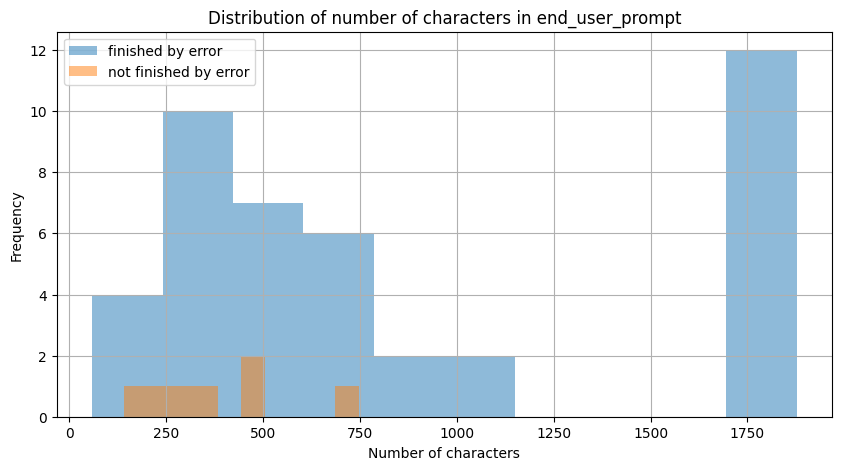

In [13]:
# runs_df.query("fewshot_mode == 'system_prompt' and num_errors == 2").end_user_prompt.tolist()
# runs_df.end_user_prompt.str.len().hist()
# plt.xlabel('Number of characters')
# plt.ylabel('Frequency')
# plt.title('Distribution of number of characters in end_user_prompt')

plt.figure(figsize=(10, 5))

runs_df[runs_df['num_errors'] == 2].end_user_prompt_num_tokens.hist(alpha=0.5, label='finished by error')
runs_df[runs_df['num_errors'] != 2].end_user_prompt_num_tokens.hist(alpha=0.5, label='not finished by error')

plt.xlabel('Number of characters')
plt.ylabel('Frequency')
plt.title('Distribution of number of characters in end_user_prompt')
plt.legend()

plt.show()


## Fewshot multi-turn

In [24]:
runs_df.query("fewshot_mode == 'multiturn' and reached_goal == True")

,agent_id,agent_type,src,tgt,path,fewshot,num_actions,num_errors,user_prompt_history,response_history,fewshot_mode,end_page,end_response,end_user_prompt,end_user_prompt_num_tokens,end_next_page,reached_goal,path_length,includes_us
31,6,LinkClickAgent,Milk,Domestic_goat,Milk;Domestic_goat,3,1,0,"[""I'm currently on the page Milk and the targe...","['{\n ""next_page"": ""Domestic_goat""\n}']",multiturn,Domestic_goat,"{\n ""next_page"": ""Domestic_goat""\n}",I'm currently on the page Milk and the target ...,285,Domestic_goat,True,1,False
38,13,LinkClickAgent,Novel,Mark_Twain_House,Novel;Miguel_de_Cervantes;William_Shakespeare;...,3,8,0,"[""I'm currently on the page Novel and the targ...","['{\n ""next_page"": ""Miguel_de_Cervantes""\n}',...",multiturn,Mark_Twain_House,"{\n ""next_page"": ""Mark_Twain_House""\n}",I'm currently on the page Mark_Twain and the t...,141,Mark_Twain_House,True,8,False
47,22,LinkClickAgent,Nile,Indonesia,Nile;Egypt;Islam;Indonesia,3,3,0,"[""I'm currently on the page Nile and the targe...","['{\n ""next_page"": ""Egypt""\n\n}', '{\n ""next...",multiturn,Indonesia,"{\n ""next_page"": ""Indonesia""\n}",I'm currently on the page Islam and the target...,458,Indonesia,True,3,False


In [28]:
print("Number of failed runs because of too many actions: ", runs_df.query("fewshot_mode == 'multiturn' and reached_goal == False and num_actions==15").count().iloc[0])
print("Number of failed runs because of too many invalid actions: ", runs_df.query("fewshot_mode == 'multiturn' and reached_goal == False and num_errors==2").count().iloc[0])

Number of failed runs because of too many actions:  1
Number of failed runs because of too many invalid actions:  21


In [99]:
runs_df.query("fewshot_mode == 'multiturn' and reached_goal == False and num_errors==0").path.tolist()

['Giant_Panda;DNA;Thomas_Jefferson;Washington, D.C.;Economics;Market;Money;Coin;India;Ramayana;Sanskrit;Vowel;French_language;Vietnam;China;Tibet']

In [30]:
runs_df.query("fewshot_mode == 'multiturn' and reached_goal == False").end_page.value_counts()

end_page
United_States              3
Phosphorus                 1
Great_comet                1
Vietnam                    1
Sound                      1
Los_Angeles,_California    1
Bristol                    1
Moscow                     1
Human                      1
Russia                     1
Tibet                      1
Rhine                      1
Ukraine                    1
Germany                    1
Physics                    1
Volcano                    1
Jerusalem                  1
France                     1
United_Kingdom             1
Time_zone                  1
Name: count, dtype: int64

In [94]:
print("Number of unparseable json outputs: ", runs_df.query("fewshot_mode == 'multiturn' and reached_goal == False and end_response_extracted_json.isna()").count().iloc[0])
print(runs_df.query("fewshot_mode == 'multiturn' and end_response_extracted_json.isna()").end_response.tolist())
runs_df.query("fewshot_mode == 'multiturn' and end_response_extracted_json.isna()")[['src', 'tgt', 'path', 'end_page', 'end_response', 'end_next_page', 'end_response_extracted_json']]

Number of unparseable json outputs:  4
['{\n  "next_page": "Sexism"', '{\n  "next_page": "Metallurgy"\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\necause zinc is a metal, you should click on the "Metallurgy" link to get closer to the target page.', '{\n  "next_page": "Sports"\n\nFrom there, you can click on "Football (soccer)" to get to the page "Boston RFC".', '{\n  "next_page": "Tobacco"']


,src,tgt,path,end_page,end_response,end_next_page,end_response_extracted_json
26,Heraclius,Gender,Heraclius;Muhammad;Women's_rights;Suffrage;Fra...,Rhine,"{\n ""next_page"": ""Sexism""",Sexism,None
41,Star_Trek__Deep_Space_Nine,Zinc,Star_Trek__Deep_Space_Nine;Soviet_Union;Moscow,Moscow,"{\n ""next_page"": ""Metallurgy""\n\n\n\n\n\n\n\n...",Metallurgy,None
42,British_Isles,Boston_RFC,British_Isles;River_Severn;Wales;Rugby_World_C...,Bristol,"{\n ""next_page"": ""Sports""\n\nFrom there, you ...",Sports,None
48,Llywelyn_the_Great,Kuru_(disease),Llywelyn_the_Great;Tower_of_London;H5N1;Vietnam,Vietnam,"{\n ""next_page"": ""Tobacco""",Tobacco,None


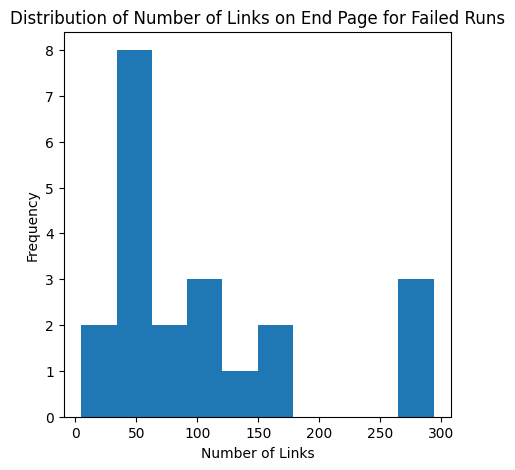

In [67]:
plt.figure(figsize=(5, 5))

runs_df.query("fewshot_mode == 'multiturn' and num_errors == 2").end_page_num_links.hist(grid=False)

plt.title('Distribution of Number of Links on End Page for Failed Runs')
plt.xlabel('Number of Links')
plt.ylabel('Frequency')

plt.show()

In [112]:
# Cases where the tgt page was in the end_page_links but the agent didn't reach it
runs_df.query("not end_page_links.isna()")[runs_df.query("not end_page_links.isna()").apply(lambda x: x['tgt'] in x['end_page_links'].split(";"), axis=1).values]

,agent_id,agent_type,src,tgt,path,fewshot,num_actions,num_errors,user_prompt_history,response_history,...,end_response,end_user_prompt,end_user_prompt_num_tokens,end_next_page,reached_goal,path_length,end_response_extracted_json,article,end_page_links,end_page_num_links
29,4,LinkClickAgent,Archbishop_of_Canterbury,Dead_Sea,Archbishop_of_Canterbury;Rome;Jerusalem,3,2,2,"[""I'm currently on the page Archbishop_of_Cant...","['{\n ""next_page"": ""Rome""\n}', '{\n ""next_pa...",...,"{\n ""next_page"": ""Dead_Sea Scrolls""\n\n}",I'm currently on the page Jerusalem and the ta...,276,Dead_Sea Scrolls,False,2,"{\n ""next_page"": ""Dead_Sea Scrolls""\n\n}",Jerusalem,Albert_Einstein;Ancient_Egypt;Arab-Israeli_con...,40.0
31,6,LinkClickAgent,Milk,Domestic_goat,Milk;Domestic_goat,3,1,0,"[""I'm currently on the page Milk and the targe...","['{\n ""next_page"": ""Domestic_goat""\n}']",...,"{\n ""next_page"": ""Domestic_goat""\n}",I'm currently on the page Milk and the target ...,285,Domestic_goat,True,1,"{\n ""next_page"": ""Domestic_goat""\n}",Domestic_goat,Animal;Bangladesh;Belize;Bible;Brain;Brazil;Bu...,34.0


# Explore Wikispeedia data

In [33]:
article_links_df = pd.read_csv(os.path.join(PATH_IN, "article_links.tsv"), sep="\t")
article_links_df['num_links'] = article_links_df.apply(lambda x: len(x['links'].split(";")), axis=1)
article_links_df.head()

,article,links,num_links
0,Áedán_mac_Gabráin,Bede;Columba;Dál_Riata;Great_Britain;Ireland;I...,11
1,Åland,20th_century;Baltic_Sea;Crimean_War;Currency;E...,19
2,Édouard_Manet,Absinthe;Beer;Claude_Monet;Diego_Velázquez;Edg...,20
3,Éire,Canada;English_language;George_VI_of_the_Unite...,8
4,Óengus_I_of_the_Picts,Dál_Riata;Durham;England;Great_Britain;Ireland...,10


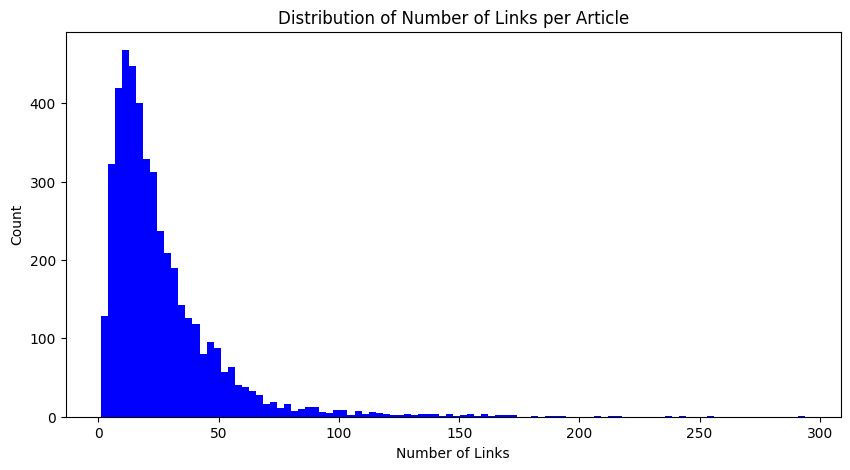

Quantiles of number of links: 0.25    11.0
0.50    19.0
0.75    33.0
0.90    51.0
0.95    67.0
Name: num_links, dtype: float64


In [117]:

plt.figure(figsize=(10, 5))
plt.hist(article_links_df['num_links'], bins=100, color='blue')#, log=True)
plt.xlabel('Number of Links')
plt.ylabel('Count')
plt.title('Distribution of Number of Links per Article')
plt.show()

print(f"Quantiles of number of links: {article_links_df['num_links'].quantile([0.25, 0.5, 0.75, 0.9, 0.95])}")

In [116]:
# average number of links per article
article_links_df['num_links'].mean()

26.13516459559625

In [47]:
# top 10 pages with most links
from pprint import pprint
pprint([(row['article'], row['num_links']) for _, row in article_links_df.sort_values(by='num_links', ascending=False).head(10).iterrows()])


[('United_States', 294),
 ('Driving_on_the_left_or_right', 255),
 ('List_of_countries', 244),
 ('List_of_circulating_currencies', 236),
 ('List_of_sovereign_states', 216),
 ('Africa', 212),
 ('List_of_countries_by_system_of_government', 207),
 ('Lebanon', 192),
 ('Interpol', 191),
 ('Armenia', 186)]


# Build paths_real_processed_df
`paths_real_df` (from Akhil) has the columns:
 - hashed_ip: user identifier
 - timestamp: time of the game
 - src, tgt: source and target pages
 - is_path_finished: whether the user reached the target page
 - failure_type: reason for failure (restart, timout, ...)
 - path: path taken (including backtracks)
 - hpl: Human Path Length (number of clicks by human, including backtracks)
 - spl: Shortest Path Length (shortest possible path length for that pair)
 - duration_in_sec: time taken by user
 - target_in_degree: number of incoming links to target page
 - user_path_rating: 1-5 rating of path difficulty by user

We're gonna add:
 - shpl: Shortest Human Path Length (lowest number of clicks by human, for that pair)
 - effective_path: path taken by user excluding backtracks
 - shortest_effective_path: shortest effective path made by human, for that pair
 - hepl: Human Effective Path Length (effective path length for that game instance)
 - shepl: Shortest Human Effective Path Length (shortest effective path length made by human, for that pair)

The final df is `paths_real_processed_df`

In [115]:
# `paths_real_df` (from Akhil) has the columns:
#  - hashed_ip: user identifier
#  - timestamp: time of the game
#  - src, tgt: source and target pages
#  - is_path_finished: whether the user reached the target page
#  - failure_type: reason for failure (restart, timout, ...)
#  - path: path taken (including backtracks)
#  - hpl: Human Path Length (number of clicks by human, including backtracks)
#  - spl: Shortest Path Length (shortest possible path length for that pair)
#  - duration_in_sec: time taken by user
#  - target_in_degree: number of incoming links to target page
#  - user_path_rating: 1-5 rating of path difficulty by user

# We're gonna add:
#  - shpl: Shortest Human Path Length (lowest number of clicks by human, for that pair)
#  - effective_path: path taken by user excluding backtracks
#  - shortest_effective_path: shortest effective path made by human, for that pair
#  - hepl: Human Effective Path Length (effective path length for that game instance)
#  - shepl: Shortest Human Effective Path Length (shortest effective path length made by human, for that pair)

# The final df is `paths_real_processed_df`

paths_real_processed_df = pd.read_csv(PATH_IN + 'paths_real_df.csv')

paths_real_processed_df["effective_path"] = paths_real_processed_df.apply(lambda row: effective_path(row["path"]), axis=1)
paths_real_processed_df["hepl"] = paths_real_processed_df.apply(lambda row: len(row["effective_path"].split(";"))-1, axis=1)

# add a column that is the shortest human path length for that pair, by choosing the minimum path_length for all games with that pair
shpl = paths_real_processed_df[paths_real_processed_df["is_path_finished"] == 1].groupby(["src", "tgt"]).agg({"hpl": "min"}).reset_index().rename(columns={"hpl": "shpl"})
shepl = paths_real_processed_df[paths_real_processed_df["is_path_finished"] == 1].groupby(["src", "tgt"]).agg({"hepl": "min"}).reset_index().rename(columns={"hepl": "shepl"})
# the shortest effective path is the path with the minimum hepl for that pair
paths_real_processed_df[paths_real_processed_df["is_path_finished"] == 1].groupby(["src", "tgt"]).agg({"hepl": "min"}).reset_index().rename(columns={"effective_path": "shortest_effective_path"})

# paths_real_processed_df = pd.merge(paths_real_processed_df, shpl, on=['src', 'tgt'], how='left')
# paths_real_processed_df = pd.merge(paths_real_processed_df, shepl, on=['src', 'tgt'], how='left')
# paths_real_processed_df = pd.merge(paths_real_processed_df, shortest_effective_path, on=['src', 'tgt'], how='left')

# paths_real_processed_df

,src,tgt,hepl
0,10th_century,11th_century,1
1,10th_century,Banknote,4
2,10th_century,Country,2
3,10th_century,Harlem_Globetrotters,3
4,10th_century,History_of_democracy,5
...,...,...,...
28713,Zulu,Language,2
28714,Zulu,Slovenia,3
28715,Zürich,Billie_Holiday,4
28716,Zürich,Mediterranean_Sea,3


In [ ]:
paths_real_processed_df.to_csv(PATH_IN + 'paths_real_processed.tsv', sep='\t', index=False)